# 01 Exploration

First look at the NASA `pscomppars` snapshot: size, missing values, distributions. The goal is to decide what the cleaning step has to handle.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Always use the newest snapshot. File names carry the download date, so sorting by name is enough.
RAW = Path("..") / "data" / "raw"
latest = sorted(RAW.glob("pscomppars_*.csv"))[-1]
df = pd.read_csv(latest)
print(latest.name, df.shape)
df.head()

pscomppars_2026-10-29.csv (6451, 17)


,pl_name,hostname,ra,dec,sy_dist,glon,glat,st_teff,st_rad,st_mass,st_spectype,pl_rade,pl_bmasse,pl_orbper,pl_eqt,discoverymethod,disc_year
0,55 Cnc b,55 Cnc,133.146837,28.329815,12.5855,196.79526,37.69663,5198.0,0.980,1.015,G8 V,13.900,263.9785,14.651552,700.00,Radial Velocity,1996
1,55 Cnc c,55 Cnc,133.146837,28.329815,12.5855,196.79526,37.69663,5198.0,0.980,1.015,G8 V,8.510,54.4738,44.393600,499.27,Radial Velocity,2004
2,55 Cnc d,55 Cnc,133.146837,28.329815,12.5855,196.79526,37.69663,5198.0,0.980,1.015,G8 V,13.000,1232.4930,4799.000000,104.85,Radial Velocity,2002
3,55 Cnc e,55 Cnc,133.146837,28.329815,12.5855,196.79526,37.69663,5172.0,0.943,0.905,G8 V,1.875,7.9900,0.736547,1958.00,Radial Velocity,2004
4,55 Cnc f,55 Cnc,133.146837,28.329815,12.5855,196.79526,37.69663,5198.0,0.980,1.015,G8 V,7.590,44.8120,260.580000,277.07,Radial Velocity,2007


## Size

pscomppars has one row per planet, so the number of host stars is smaller than the number of rows.

In [2]:
print("planets:", len(df))
print("host stars:", df["hostname"].nunique())
print("planets per star, top 5:")
df["hostname"].value_counts().head(5)

planets: 6451
host stars: 4847
planets per star, top 5:


hostname
KOI-351       8
TRAPPIST-1    7
Kepler-11     6
HIP 41378     6
HD 191939     6
Name: count, dtype: int64

## Missing values

This decides the fallbacks: distance is mandatory for the map, star colour needs a plan B when the spectral type is missing.

In [3]:
missing = df.isna().sum().to_frame("missing")
missing["share_%"] = (missing["missing"] / len(df) * 100).round(1)
missing.sort_values("missing", ascending=False)

,missing,share_%
st_spectype,4041,62.6
pl_eqt,540,8.4
pl_orbper,354,5.5
st_rad,332,5.1
st_teff,307,4.8
pl_rade,50,0.8
pl_bmasse,30,0.5
sy_dist,28,0.4
st_mass,9,0.1
pl_name,0,0.0


## Distance

Rows without `sy_dist` cannot be placed. The range is huge, which is why a log scale option is planned.

In [4]:
print("no distance:", df["sy_dist"].isna().sum())
df["sy_dist"].describe()

no distance: 28


count    6423.000000
mean      704.833229
std      1230.179410
min         1.301190
25%        99.643550
50%       349.000000
75%       817.261000
max      8500.000000
Name: sy_dist, dtype: float64

Text(0, 0.5, 'planets')

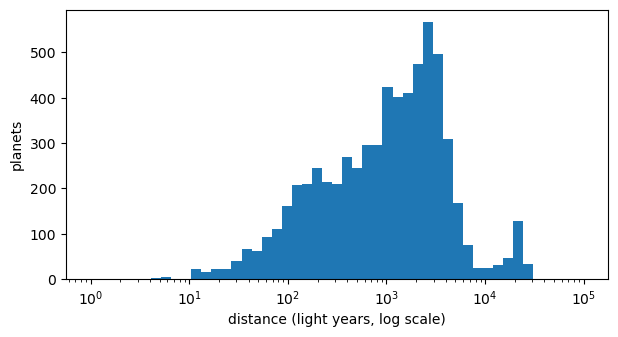

In [5]:
# Parsec to light years, same factor as in the project document.
ly = df["sy_dist"] * 3.2616
ax = ly.plot.hist(bins=np.logspace(0, 5, 50), logx=True, figsize=(7, 3.5))
ax.set_xlabel("distance (light years, log scale)")
ax.set_ylabel("planets")

## Discovery method and year

In [6]:
df["discoverymethod"].value_counts()

discoverymethod
Transit                          4785
Radial Velocity                  1204
Microlensing                      292
Imaging                            98
Transit Timing Variations          29
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Pulsar Timing                       8
Astrometry                          6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64

<Axes: xlabel='disc_year'>

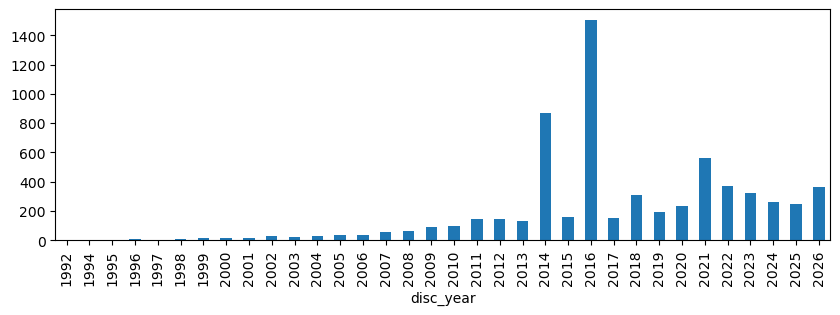

In [7]:
df.groupby("disc_year").size().plot.bar(figsize=(10, 3))

## Star colour source

Spectral type is mostly missing, effective temperature is not. Colour will be derived from `st_teff`.

In [8]:
print("spectral type present:", df["st_spectype"].notna().sum())
print("temperature present:", df["st_teff"].notna().sum())
df["st_teff"].describe()

spectral type present: 2410
temperature present: 6144


count     6144.000000
mean      5389.434811
std       1719.078393
min        415.000000
25%       4893.750000
50%       5544.000000
75%       5900.000000
max      57000.000000
Name: st_teff, dtype: float64

## Findings

- Drop or flag rows without `sy_dist` (see count above).
- Colour from `st_teff`, with a default for the rest.
- One position per `hostname`, planets attached to the star.